# High-rate hyperbolic Floquet — logical error rate vs p

Curves of logical error rate vs physical error rate `p` for each `[[n,k,d]]` code in the
`threshold_hyperbolic_floquet` collection.

In [21]:
import ast
import datetime
import glob
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sinter

In [22]:
CSV_GLOB = '../out/collection/threshold_hyperbolic_floquet,*.csv'

BIAS = 10

files = sorted(glob.glob(CSV_GLOB))
if not files:
    raise FileNotFoundError(f'No files matched: {CSV_GLOB}')

df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

# Merge repeated runs by strong_id (same circuit + decoder).
df = df.groupby('strong_id').agg({
    'shots': 'sum',
    'errors': 'sum',
    'discards': 'sum',
    'seconds': 'sum',
    'decoder': 'first',
    'json_metadata': 'first',
}).reset_index()

meta = df['json_metadata'].apply(lambda s: ast.literal_eval(s) if isinstance(s, str) else dict(s))
df['p'] = meta.apply(lambda m: m.get('p'))
df['p_bell_z'] = meta.apply(lambda m: m.get('p_bell_z'))
df['bias'] = meta.apply(lambda m: m.get('bias'))

_NKD = re.compile(r'n=(\d+)_k=(\d+)_d=(\d+)')
def _nkd(m):
    mm = _NKD.search(m.get('input_circuit', ''))
    if not mm:
        return (None, None, None)
    return tuple(int(x) for x in mm.groups())

df[['n', 'k', 'd']] = pd.DataFrame(meta.apply(_nkd).tolist(), index=df.index)
df['code'] = df.apply(lambda r: f"[[{r['n']},{r['k']},{r['d']}]]", axis=1)

df['pL'] = df['errors'] / df['shots'].clip(lower=1)
df['pL_err'] = np.sqrt(np.clip(df['pL'] * (1 - df['pL']), 0, None) / df['shots'].clip(lower=1))

available_biases = sorted(df['bias'].dropna().unique())
df = df[np.isclose(df['bias'].astype(float), float(BIAS))].reset_index(drop=True)
df = df[df['pL'] > 0].reset_index(drop=True)
if df.empty:
    raise ValueError(f'no rows for BIAS={BIAS}; available biases: {available_biases}')

code_order = (
    df.drop_duplicates('code')
      .sort_values('n')['code']
      .tolist()
)
print(f'{len(df)} rows; bias={BIAS:g} (available: {available_biases}); codes={code_order}')
df.head()

81 rows; bias=10 (available: [np.float64(10.0), np.float64(100.0)]); codes=['[[64,10,2]]', '[[256,10,4]]', '[[576,10,6]]', '[[1024,10,8]]', '[[1600,10,10]]', '[[2304,10,12]]']


,strong_id,shots,errors,discards,seconds,decoder,json_metadata,p,p_bell_z,bias,n,k,d,code,pL,pL_err
0,01905565d685af0014dfe59f2016765fefe509e463ceec...,6486,781,0,0.092128,pymatching,"{'p': 0.00013593563908785255, 'p_bell_z': 0.00...",0.000136,0.001359,10.0,64,10,2,"[[64,10,2]]",0.120413,0.004041
1,0685e3b599174f2340afb81a553bdc20762ec1f9f28adc...,383,382,0,9560.887082,pymatching,"{'p': 0.003981071705534973, 'p_bell_z': 0.0398...",0.003981,0.039811,10.0,2304,10,12,"[[2304,10,12]]",0.997389,0.002608
2,0c3a1e2e0640a7db2d6ba14dd8dc98d3ec3c4e8462db9c...,551,550,0,7.169173,pymatching,"{'p': 0.0029286445646252374, 'p_bell_z': 0.029...",0.002929,0.029286,10.0,256,10,4,"[[256,10,4]]",0.998185,0.001813
3,0d3af9c53fac327ae181b193e3e723111c261fea6f438d...,1365,776,0,0.066533,pymatching,"{'p': 0.0003414548873833601, 'p_bell_z': 0.003...",0.000341,0.003415,10.0,64,10,2,"[[64,10,2]]",0.568498,0.013406
4,10efc3a7eb5fc3d1ff2c50ad0756fa1b5492168a6b561c...,530,530,0,197.684815,pymatching,"{'p': 0.003981071705534973, 'p_bell_z': 0.0398...",0.003981,0.039811,10.0,576,10,6,"[[576,10,6]]",1.000000,0.000000


Saved ../out/figures/20260625_high_rate_bias10.pdf


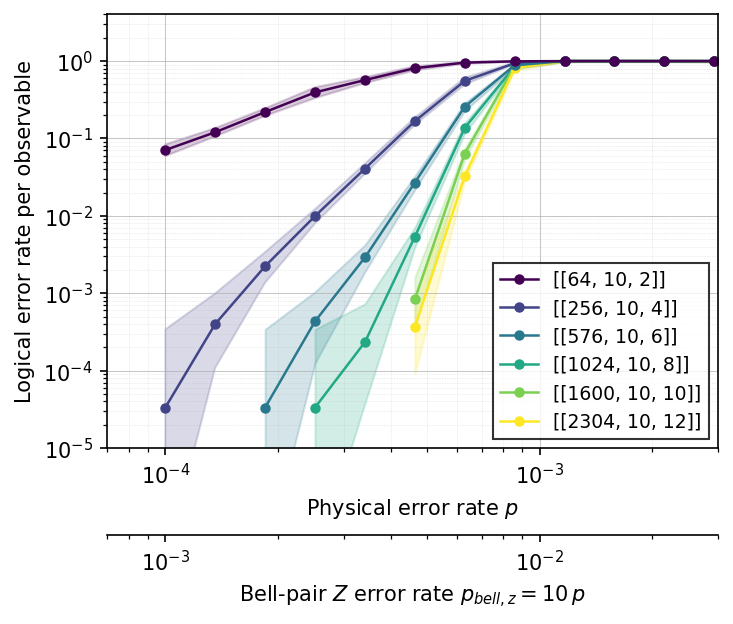

In [25]:
plt.rcParams.update({
    'font.size': 10,
    'axes.labelsize': 10,
    'axes.titlesize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9,
})

cmap = plt.get_cmap('viridis')
colors = {code: cmap(i / max(1, len(code_order) - 1)) for i, code in enumerate(code_order)}


def _meta(row):
    m = ast.literal_eval(row['json_metadata']) if isinstance(row['json_metadata'], str) else dict(row['json_metadata'])
    m['n'] = int(row['n'])
    m['k'] = int(row['k'])
    m['expected_distance'] = int(row['d'])
    return m


tasks = [
    sinter.TaskStats(
        strong_id=row['strong_id'],
        decoder=row['decoder'],
        json_metadata=_meta(row),
        shots=int(row['shots']),
        errors=int(row['errors']),
        discards=int(row['discards']),
        seconds=float(row['seconds']),
    )
    for _, row in df.iterrows()
]


def group_func(stat):
    n = stat.json_metadata['n']
    k = stat.json_metadata['k']
    d = stat.json_metadata['expected_distance']
    return f'[[{n}, {k}, {d}]]'


def plot_args_func(index, group_key, group_stats):
    # The viridis lookup uses the same labels group_func produces (no spaces).
    key = group_key.replace(' ', '')
    return {'color': colors.get(key, 'k'), 'marker': 'o', 'markersize': 4, 'linewidth': 1.2}


fig, ax = plt.subplots(1, 1, figsize=(5, 4))

sinter.plot_error_rate(
    ax=ax,
    stats=tasks,
    x_func=lambda s: s.json_metadata['p'],
    group_func=group_func,
    plot_args_func=plot_args_func,
    failure_units_per_shot_func=lambda s: 1,
    failure_values_func=lambda s: s.json_metadata['k'],
)

ax.loglog()

# Sort legend by n.
handles, labels = ax.get_legend_handles_labels()
def _extract_n(lbl):
    m = re.search(r'\[\[(\d+),', lbl)
    return int(m.group(1)) if m else 0
sorted_pairs = sorted(zip(handles, labels), key=lambda hl: _extract_n(hl[1]))
if sorted_pairs:
    sorted_handles, sorted_labels = zip(*sorted_pairs)
    ax.legend(sorted_handles, sorted_labels, loc='lower right',
              frameon=True, edgecolor='black', fancybox=False)

p_min = float(df['p'].min())
p_max = float(df['p'].max())
ax.set_xlim(p_min * 0.7, 3e-3)
ax.set_ylim(1e-5, 4)

ax.set_xlabel(r'Physical error rate $p$')
ax.set_ylabel(r'Logical error rate per observable')
ax.grid(which='major', linestyle='-', linewidth=0.5, alpha=0.7)
ax.grid(which='minor', linestyle=':', linewidth=0.3, alpha=0.5)

# Second x-axis underneath, showing p_bell_z = BIAS * p.
fig.tight_layout()
fig.subplots_adjust(bottom=0.24)

ax_pbz = ax.secondary_xaxis(
    -0.20,
    functions=(lambda p: p * BIAS, lambda pbz: pbz / BIAS),
)
ax_pbz.set_xlabel(rf'Bell-pair $Z$ error rate $p_{{bell,z}} = {BIAS:g}\,p$')

fig.set_dpi(150)

out_dir = Path('../out/figures')
out_dir.mkdir(parents=True, exist_ok=True)
date = datetime.date.today().strftime('%Y%m%d')
out_path = out_dir / f'{date}_high_rate_bias{int(BIAS)}.pdf'
fig.savefig(out_path, bbox_inches='tight')
print(f'Saved {out_path}')
plt.show()

In [4]:
df.query("1e-4 < p < 2e-4 and n==576")

,strong_id,shots,errors,discards,seconds,decoder,json_metadata,p,p_bell_z,bias,n,k,d,code,pL,pL_err
35,77c933ffe679cedd88b76492ed40ab77b205475aa18dde...,30000,1,0,4.330466,pymatching,"{'p': 0.00018478497974222906, 'p_bell_z': 0.00...",0.000185,0.001848,10.0,576,10,6,"[[576,10,6]]",0.000033,0.000033
